# THỰC NGHIỆM PCA TRÊN BỘ DỮ LIỆU WINE

**Mục tiêu:** Trình bày lại quy trình trong project `pca-machine-learning`: đọc dữ liệu Wine, chuẩn hóa 13 thuộc tính, thực hiện PCA thủ công bằng phân rã trị riêng, thực hiện PCA bằng scikit-learn, trực quan hóa và so sánh.

**Dữ liệu:** 178 mẫu, 13 đặc trưng định lượng, 3 lớp (`target`). Notebook sử dụng dữ liệu CSV trong chính project; không tải bộ dữ liệu khác.

## 1. Khởi tạo thư viện và đường dẫn

Đặt Notebook tại `notebooks/pca_wine_analysis.ipynb`. Ô dưới tự tìm thư mục gốc project, nên có thể chạy Jupyter từ thư mục gốc hoặc từ `notebooks/`.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Tìm thư mục gốc theo file dữ liệu có sẵn
candidates = [Path.cwd(), Path.cwd().parent]
PROJECT_ROOT = next((p for p in candidates if (p / "data" / "raw" / "wine.csv").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Không tìm thấy data/raw/wine.csv. Hãy mở Jupyter tại thư mục project hoặc notebooks/.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from pca.data_loader import load_wine_data
from pca.preprocessing import standardize_data

print("Thư mục project:", PROJECT_ROOT)

Thư mục project: /Users/nguyenbathienlan/Documents/Kỳ 1 2026-2027/học máy gk/pca-machine-learning


## 2. Đọc và khám phá dữ liệu Wine

Dùng hàm `load_wine_data()` từ `pca/data_loader.py` của nhóm để tách ma trận đặc trưng `X`, nhãn `y` và tên các thuộc tính.

In [2]:
X, y, feature_names = load_wine_data()
df_original = pd.DataFrame(X, columns=feature_names)
df_original.insert(0, "target", y)
print("Kích thước X:", X.shape)
print("Kích thước y:", y.shape)
print("Số giá trị thiếu:", int(df_original.isna().sum().sum()))
print("Số mẫu theo lớp:")
print(df_original["target"].value_counts().sort_index())
display(df_original.head())

Kích thước X: (178, 13)
Kích thước y: (178,)
Số giá trị thiếu: 0
Số mẫu theo lớp:
target
1    59
2    71
3    48
Name: count, dtype: int64


,target,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline
0,1,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,1,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,1,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,1,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


## 3. Chuẩn hóa dữ liệu

Các thuộc tính Wine có thang đo khác nhau, nên cần chuẩn hóa trước PCA. Dùng chính hàm `standardize_data()` của nhóm (`StandardScaler`): mỗi thuộc tính có trung bình xấp xỉ 0 và độ lệch chuẩn xấp xỉ 1.

In [3]:
X_scaled = standardize_data(X)
df_scaled = pd.DataFrame(X_scaled, columns=feature_names)
df_scaled.insert(0, "target", y)
print("Kích thước sau chuẩn hóa:", X_scaled.shape)
print("Trung bình lớn nhất theo trị tuyệt đối:", np.abs(X_scaled.mean(axis=0)).max())
print("Độ lệch chuẩn:", np.round(X_scaled.std(axis=0), 4))
display(df_scaled.head())

Kích thước sau chuẩn hóa: (178, 13)
Trung bình lớn nhất theo trị tuyệt đối: 8.382807556720283e-16
Độ lệch chuẩn: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


,target,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline
0,1,1.518613,-0.562250,0.232053,-1.169593,1.913905,0.808997,1.034819,-0.659563,1.224884,0.251717,0.362177,1.847920,1.013009
1,1,0.246290,-0.499413,-0.827996,-2.490847,0.018145,0.568648,0.733629,-0.820719,-0.544721,-0.293321,0.406051,1.113449,0.965242
2,1,0.196879,0.021231,1.109334,-0.268738,0.088358,0.808997,1.215533,-0.498407,2.135968,0.269020,0.318304,0.788587,1.395148
3,1,1.691550,-0.346811,0.487926,-0.809251,0.930918,2.491446,1.466525,-0.981875,1.032155,1.186068,-0.427544,1.184071,2.334574
4,1,0.295700,0.227694,1.840403,0.451946,1.281985,0.808997,0.663351,0.226796,0.401404,-0.319276,0.362177,0.449601,-0.037874


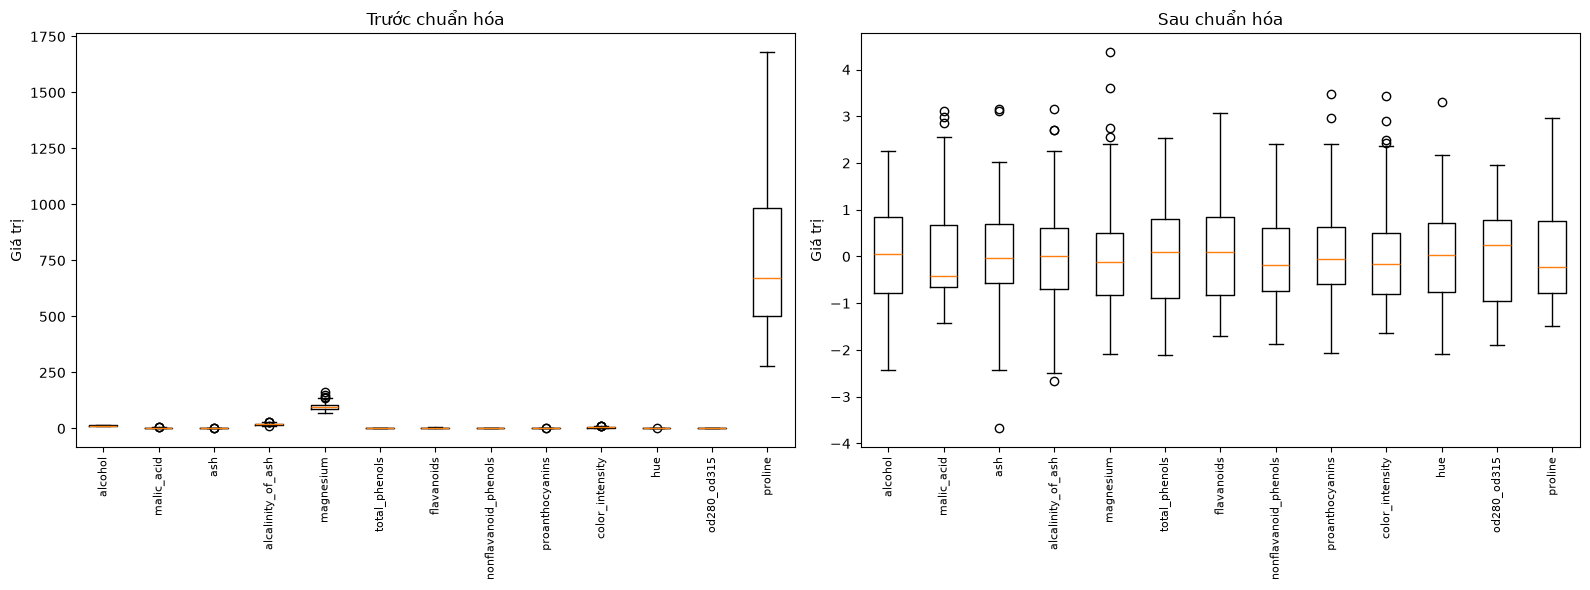

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].boxplot(X)
axes[0].set_title("Trước chuẩn hóa")
axes[0].set_ylabel("Giá trị")
axes[1].boxplot(X_scaled)
axes[1].set_title("Sau chuẩn hóa")
axes[1].set_ylabel("Giá trị")
for ax in axes:
    ax.set_xticks(range(1, len(feature_names) + 1))
    ax.set_xticklabels(feature_names, rotation=90, fontsize=8)
plt.tight_layout()
plt.show()

## 4. PCA thủ công: ma trận hiệp phương sai

Theo `pca/pca_manual.py`, tính ma trận hiệp phương sai của dữ liệu chuẩn hóa bằng `np.cov(X_scaled, rowvar=False)`. Ma trận có kích thước 13 × 13.

Kích thước ma trận hiệp phương sai: (13, 13)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline
alcohol,1.0056,0.0949,0.2127,-0.3120,0.2723,0.2907,0.2382,-0.1568,0.1375,0.5495,-0.0722,0.0728,0.6474
malic_acid,0.0949,1.0056,0.1650,0.2901,-0.0549,-0.3371,-0.4133,0.2946,-0.2220,0.2504,-0.5645,-0.3708,-0.1931
ash,0.2127,0.1650,1.0056,0.4459,0.2882,0.1297,0.1157,0.1873,0.0097,0.2603,-0.0751,0.0039,0.2249
alcalinity_of_ash,-0.3120,0.2901,0.4459,1.0056,-0.0838,-0.3229,-0.3534,0.3640,-0.1984,0.0188,-0.2755,-0.2783,-0.4431
magnesium,0.2723,-0.0549,0.2882,-0.0838,1.0056,0.2156,0.1969,-0.2577,0.2378,0.2011,0.0557,0.0664,0.3956
total_phenols,0.2907,-0.3371,0.1297,-0.3229,0.2156,1.0056,0.8694,-0.4525,0.6159,-0.0554,0.4361,0.7039,0.5009
flavanoids,0.2382,-0.4133,0.1157,-0.3534,0.1969,0.8694,1.0056,-0.5409,0.6564,-0.1734,0.5465,0.7916,0.4970
nonflavanoid_phenols,-0.1568,0.2946,0.1873,0.3640,-0.2577,-0.4525,-0.5409,1.0056,-0.3679,0.1398,-0.2641,-0.5061,-0.3131
proanthocyanins,0.1375,-0.2220,0.0097,-0.1984,0.2378,0.6159,0.6564,-0.3679,1.0056,-0.0254,0.2972,0.5220,0.3323
color_intensity,0.5495,0.2504,0.2603,0.0188,0.2011,-0.0554,-0.1734,0.1398,-0.0254,1.0056,-0.5248,-0.4312,0.3179


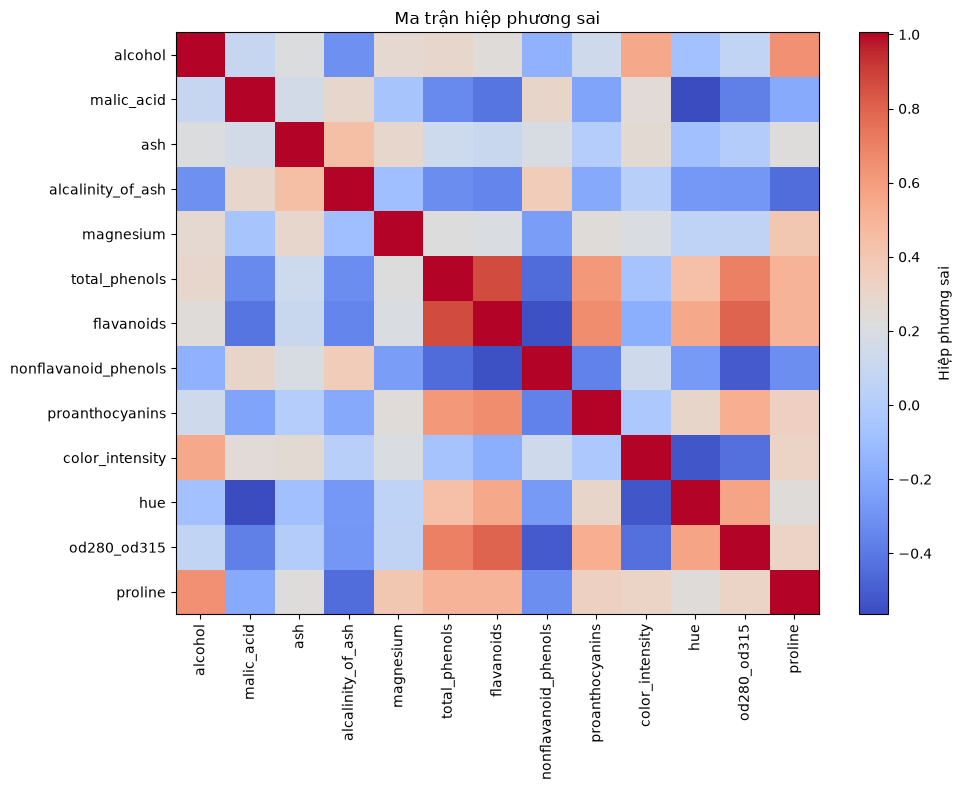

In [5]:
cov_matrix = np.cov(X_scaled, rowvar=False)
print("Kích thước ma trận hiệp phương sai:", cov_matrix.shape)
display(pd.DataFrame(cov_matrix, index=feature_names, columns=feature_names).round(4))
plt.figure(figsize=(10, 8))
plt.imshow(cov_matrix, cmap="coolwarm", aspect="auto")
plt.colorbar(label="Hiệp phương sai")
plt.xticks(range(len(feature_names)), feature_names, rotation=90)
plt.yticks(range(len(feature_names)), feature_names)
plt.title("Ma trận hiệp phương sai")
plt.tight_layout()
plt.show()

## 5. PCA thủ công: trị riêng, vector riêng và phép chiếu

Dùng `np.linalg.eigh()` cho ma trận đối xứng, sắp xếp trị riêng giảm dần, chọn hai vector riêng tương ứng với hai trị riêng lớn nhất làm ma trận chiếu `W`, sau đó tính `X_pca_manual = X_scaled @ W`.

In [6]:
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)
indices = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[indices]
eigenvectors = eigenvectors[:, indices]
manual_ratio = eigenvalues / eigenvalues.sum()
W = eigenvectors[:, :2]
X_pca_manual = X_scaled @ W
print("Trị riêng:", np.round(eigenvalues, 4))
print("Kích thước W:", W.shape)
print("Kích thước sau PCA thủ công:", X_pca_manual.shape)
print(f"PC1: {manual_ratio[0]*100:.2f}% | PC2: {manual_ratio[1]*100:.2f}%")
print(f"Tổng phương sai 2 PC: {manual_ratio[:2].sum()*100:.2f}%")
df_manual = pd.DataFrame(X_pca_manual, columns=["PC1", "PC2"])
df_manual["target"] = y
display(df_manual.head())

Trị riêng: [4.7324 2.5111 1.4542 0.9242 0.858  0.6453 0.5541 0.3505 0.2905 0.2523
 0.2271 0.1697 0.104 ]
Kích thước W: (13, 2)
Kích thước sau PCA thủ công: (178, 2)
PC1: 36.20% | PC2: 19.21%
Tổng phương sai 2 PC: 55.41%


,PC1,PC2,target
0,-3.316751,1.443463,1
1,-2.209465,-0.333393,1
2,-2.516740,1.031151,1
3,-3.757066,2.756372,1
4,-1.008908,0.869831,1


## 6. PCA bằng scikit-learn

Tương tự `pca/pca_sklearn.py`: dùng `PCA()` để lấy phương sai của 13 thành phần, và `PCA(n_components=2)` để giảm dữ liệu từ 13 chiều xuống 2 chiều.

In [7]:
pca_full = PCA()
pca_full.fit(X_scaled)
sklearn_ratio = pca_full.explained_variance_ratio_
pca_2d = PCA(n_components=2)
X_pca_sklearn = pca_2d.fit_transform(X_scaled)
df_sklearn = pd.DataFrame(X_pca_sklearn, columns=["PC1", "PC2"])
df_sklearn["target"] = y
print("Kích thước sau PCA sklearn:", X_pca_sklearn.shape)
print(f"PC1: {sklearn_ratio[0]*100:.2f}% | PC2: {sklearn_ratio[1]*100:.2f}%")
print(f"Tổng phương sai 2 PC: {sklearn_ratio[:2].sum()*100:.2f}%")
display(df_sklearn.head())

Kích thước sau PCA sklearn: (178, 2)
PC1: 36.20% | PC2: 19.21%
Tổng phương sai 2 PC: 55.41%


,PC1,PC2,target
0,3.316751,1.443463,1
1,2.209465,-0.333393,1
2,2.516740,1.031151,1
3,3.757066,2.756372,1
4,1.008908,0.869831,1


## 7. Trực quan hóa dữ liệu sau PCA

Mỗi điểm biểu diễn một mẫu Wine; màu sắc thể hiện lớp `target`. Hướng trục PC có thể bị đảo dấu giữa hai phương pháp mà không ảnh hưởng đến tính đúng đắn của PCA.

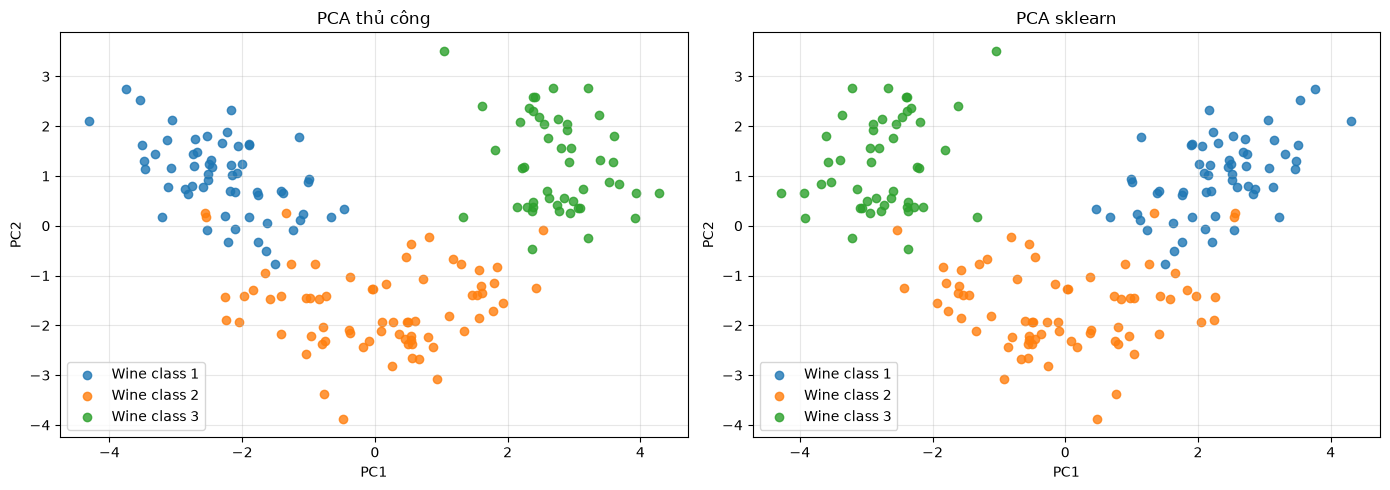

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, frame, title in zip(axes, [df_manual, df_sklearn], ["PCA thủ công", "PCA sklearn"]):
    for label in sorted(frame["target"].unique()):
        subset = frame[frame["target"] == label]
        ax.scatter(subset["PC1"], subset["PC2"], label=f"Wine class {label}", alpha=0.8)
    ax.set(xlabel="PC1", ylabel="PC2", title=title)
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 8. So sánh tỷ lệ phương sai giải thích

So sánh 13 thành phần chính của hai cách tính. Sai lệch rất nhỏ (cỡ sai số số thực của máy tính) cho thấy các tỷ lệ phương sai khớp nhau.

,Principal Component,Manual PCA,Sklearn PCA,Difference
0,PC1,0.361988,0.361988,1.110223e-16
1,PC2,0.192075,0.192075,0.000000e+00
2,PC3,0.111236,0.111236,6.938894e-17
3,PC4,0.070690,0.070690,4.163336e-17
4,PC5,0.065633,0.065633,2.775558e-17
5,PC6,0.049358,0.049358,0.000000e+00
6,PC7,0.042387,0.042387,6.938894e-18
7,PC8,0.026807,0.026807,1.040834e-17
8,PC9,0.022222,0.022222,6.938894e-18
9,PC10,0.019300,0.019300,1.040834e-17


Sai lệch tối đa: 1.1102230246251565e-16
Tương đương trong sai số 1e-6: True


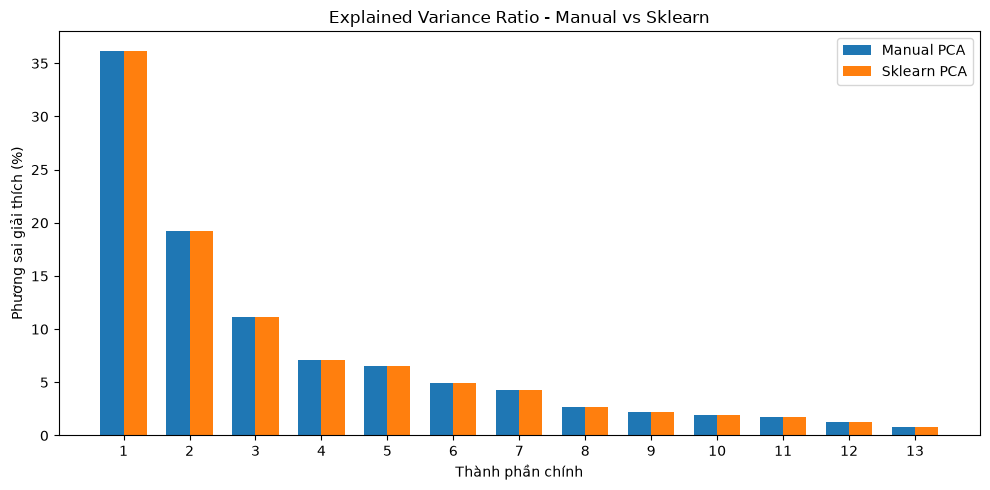

In [9]:
pcs = np.arange(1, len(manual_ratio) + 1)
comparison = pd.DataFrame({
    "Principal Component": [f"PC{i}" for i in pcs],
    "Manual PCA": manual_ratio,
    "Sklearn PCA": sklearn_ratio,
    "Difference": np.abs(manual_ratio - sklearn_ratio),
})
display(comparison)
print("Sai lệch tối đa:", comparison["Difference"].max())
print("Tương đương trong sai số 1e-6:", np.allclose(manual_ratio, sklearn_ratio, atol=1e-6))

plt.figure(figsize=(10, 5))
width = 0.35
plt.bar(pcs - width/2, manual_ratio*100, width, label="Manual PCA")
plt.bar(pcs + width/2, sklearn_ratio*100, width, label="Sklearn PCA")
plt.xlabel("Thành phần chính")
plt.ylabel("Phương sai giải thích (%)")
plt.title("Explained Variance Ratio - Manual vs Sklearn")
plt.xticks(pcs)
plt.legend()
plt.tight_layout()
plt.show()

## 9. Phương sai giải thích tích lũy

Biểu đồ cho biết số thành phần chính cần giữ lại để đạt một tỷ lệ phương sai nhất định. Trong thực nghiệm này, nhóm chọn 2 PC để **trực quan hóa 2D**, không phải để đạt ngưỡng 95%.

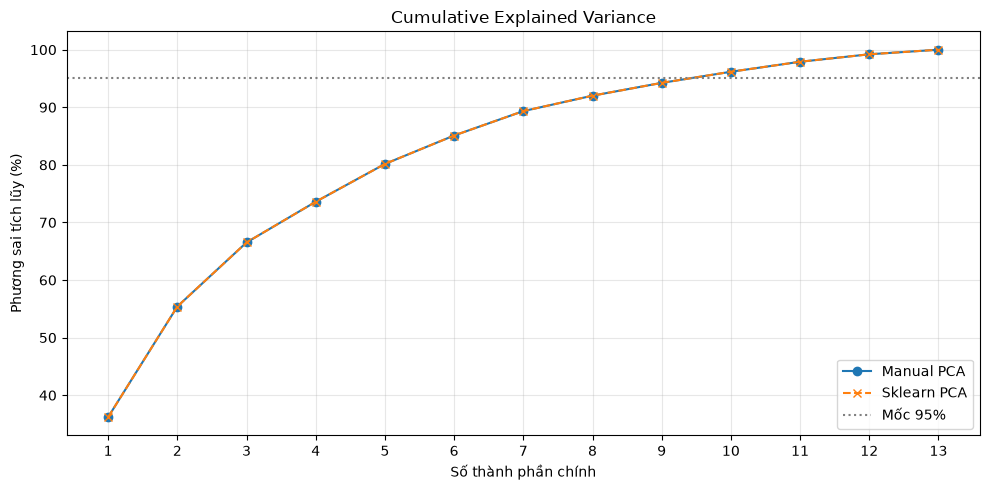

Số PC tối thiểu để đạt >= 95%: 10


In [10]:
plt.figure(figsize=(10, 5))
plt.plot(pcs, np.cumsum(manual_ratio)*100, marker="o", label="Manual PCA")
plt.plot(pcs, np.cumsum(sklearn_ratio)*100, marker="x", linestyle="--", label="Sklearn PCA")
plt.axhline(95, linestyle=":", color="gray", label="Mốc 95%")
plt.xlabel("Số thành phần chính")
plt.ylabel("Phương sai tích lũy (%)")
plt.title("Cumulative Explained Variance")
plt.xticks(pcs)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()
print("Số PC tối thiểu để đạt >= 95%:", np.searchsorted(np.cumsum(sklearn_ratio), 0.95) + 1)

## 10. Kết luận

- Dữ liệu Wine có **178 mẫu, 13 đặc trưng và 3 lớp**.
- Sau chuẩn hóa, PCA thủ công và PCA scikit-learn đều giảm dữ liệu xuống **2 thành phần chính**.
- **PC1 giải thích khoảng 36,20%**, **PC2 khoảng 19,21%**; tổng cộng **khoảng 55,41% phương sai**.
- Hai phương pháp có tỷ lệ phương sai giải thích gần như trùng khớp; dấu của vector riêng có thể khác nhau mà không làm sai kết quả.
- Hai PC giúp quan sát dữ liệu trên mặt phẳng 2D. Nếu cần giữ ít nhất 95% phương sai, phải chọn nhiều thành phần hơn.

**Nguồn triển khai:** `pca/data_loader.py`, `pca/preprocessing.py`, `pca/pca_manual.py`, `pca/pca_sklearn.py` và `experiments/run_experiment.py` trong project của nhóm.